# Delivery Center: onde receita, cancelamento e capacidade se encontram?

**Pergunta de negócio:** onde priorizar capacidade e melhoria operacional para proteger o valor dos pedidos? Vamos localizar receita e cancelamentos por canal, segmento e hub; cruzar demanda por hora com o ciclo de entrega; e medir custo e distância por modal.

O nome histórico da pasta é “iFood”, mas a base é **Delivery Center**, uma operação multicanal. Os resultados não descrevem toda a operação do iFood. A decisão proposta é orientar uma investigação de capacidade por horário/hub e de dependência comercial das lojas.

## Dados, licença e contrato das métricas

- **Fonte:** [Delivery Center: Food & Goods orders in Brazil, publicado por nosbielcs no Kaggle](https://www.kaggle.com/datasets/nosbielcs/brazilian-delivery-center). Sete CSVs locais: pedidos, pagamentos, entregas, entregadores, lojas, canais e hubs.
- **Licença:** o catálogo público do Kaggle informa **“Data files © Original Authors”** (`copyright-authors`, consulta em 24/11/2026). Isso não equivale a licença aberta de redistribuição; os direitos permanecem dos autores. Os arquivos já existentes são usados para estudo; a licença do template do site não cobre os dados.
- **Período:** calculado abaixo a partir de `order_moment_created`; a unidade analítica principal é **um pedido**, não um pagamento nem uma tentativa de entrega.
- **Faturamento comparável ao Power BI/dashboard:** `SUM(orders.order_amount)`, **todos os status, inclusive CANCELED**. É valor bruto dos pedidos registrados, não receita líquida realizada. O valor apenas de FINISHED aparece separadamente. Não removemos valores extremos monetários para manter reconciliação.
- **Por que não payments?** Um pedido pode ter vários meios/registros de pagamento; `payment_amount` representa movimentação financeira com status próprio. Taxas, estornos, vouchers e cobertura das chaves impedem tratar sua soma como a mesma métrica de pedidos. Pagamentos são agregados por chave antes de qualquer comparação.
- **Limpeza:** `usecols` e tipos explícitos no CSV de pedidos (~90 MB); datas com formato explícito; chaves únicas e junções `many_to_one` validadas; dimensões ausentes marcadas. Tempos em **minutos**, validados contra os timestamps. Outliers do ciclo recebem um recorte operacional explícito, sem excluir pedidos dos totais de receita/cancelamento.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, str(Path.cwd().parents[1] / 'scripts'))
from formatacao_br import fmt_int, fmt_num, fmt_brl, fmt_pct, tabela_br, formatar_eixos
from IPython.display import display, Markdown

BASE = Path('.')
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})

def ler(nome, tipos):
    try:
        return pd.read_csv(BASE / f'{nome}.csv', usecols=list(tipos), dtype=tipos)
    except UnicodeDecodeError:
        return pd.read_csv(BASE / f'{nome}.csv', usecols=list(tipos), dtype=tipos, encoding='latin-1')

tipos_pedidos = dict(order_id='int64', store_id='int64', channel_id='int64',
    payment_order_id='int64', delivery_order_id='int64', order_status='string',
    order_amount='float64', order_delivery_cost='float64', order_created_hour='int8',
    order_moment_created='string', order_moment_finished='string',
    order_metric_cycle_time='float64', order_metric_production_time='float64',
    order_metric_transit_time='float64')
orders = ler('orders', tipos_pedidos)
stores = ler('stores', dict(store_id='int64', hub_id='int64', store_name='string', store_segment='string'))
channels = ler('channels', dict(channel_id='int64', channel_name='string', channel_type='string'))
hubs = ler('hubs', dict(hub_id='int64', hub_name='string', hub_city='string'))
deliveries = ler('deliveries', dict(delivery_id='int64', delivery_order_id='int64', driver_id='Int64',
    delivery_distance_meters='float64', delivery_status='string'))
drivers = ler('drivers', dict(driver_id='int64', driver_modal='string'))
payments = ler('payments', dict(payment_id='int64', payment_order_id='int64',
    payment_amount='float64', payment_status='string'))
for frame, chave in [(orders, 'order_id'), (orders, 'delivery_order_id'), (stores, 'store_id'),
                      (channels, 'channel_id'), (hubs, 'hub_id'), (drivers, 'driver_id'),
                      (deliveries, 'delivery_id'), (payments, 'payment_id')]:
    assert frame[chave].notna().all() and frame[chave].is_unique, chave
for coluna in ['order_moment_created', 'order_moment_finished']:
    orders[coluna] = pd.to_datetime(orders[coluna], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')
assert orders.order_moment_created.notna().all()
pedidos = (orders.merge(stores, on='store_id', how='left', validate='many_to_one')
    .merge(channels, on='channel_id', how='left', validate='many_to_one')
    .merge(hubs, on='hub_id', how='left', validate='many_to_one'))
dimensoes = ['store_name', 'store_segment', 'channel_name', 'channel_type', 'hub_name', 'hub_city']
faltas = pedidos[dimensoes].isna().sum()
pedidos[dimensoes] = pedidos[dimensoes].fillna('Não informado')
pedidos['cancelado'] = pedidos.order_status.eq('CANCELED')
pedidos['dia_semana'] = pedidos.order_moment_created.dt.day_of_week
receita = pedidos.order_amount.sum()
concluidos = pedidos.order_status.eq('FINISHED')
print(f'Período: {orders.order_moment_created.min():%d/%m/%Y %H:%M:%S} a {orders.order_moment_created.max():%d/%m/%Y %H:%M:%S}')
print(f'{fmt_int(len(pedidos))} pedidos; faturamento bruto {fmt_brl(receita)}; '
      f'FINISHED {fmt_brl(pedidos.loc[concluidos, "order_amount"].sum())}')
print('Dimensões ausentes antes do preenchimento:', {k: fmt_int(v) for k, v in faltas.items()})
assert len(pedidos) == len(orders)
assert np.isclose(receita, orders.order_amount.sum())

Período: 01/01/2021 00:01:36 a 30/04/2021 23:59:48
368.999 pedidos; faturamento bruto R$ 38.800.730,73; FINISHED R$ 35.293.230,28
Dimensões ausentes antes do preenchimento: {'store_name': '0', 'store_segment': '0', 'channel_name': '0', 'channel_type': '0', 'hub_name': '0', 'hub_city': '0'}


### Pagamentos são uma reconciliação separada

A tabela abaixo compara registros financeiros e pedidos sem multiplicar a receita. A diferença entre somas não é margem nem inadimplência: temos conceitos e coberturas distintos. A participação do maior pedido também sinaliza quanto o total bruto depende de um registro extremo.

In [2]:
pag_por_pedido = payments.groupby('payment_order_id', as_index=False).agg(
    pagamentos=('payment_id', 'size'), valor_pagamentos=('payment_amount', 'sum'))
reconciliacao = orders[['payment_order_id', 'order_amount']].merge(
    pag_por_pedido, on='payment_order_id', how='left', validate='many_to_one')
display(pd.Series({
    'Valor bruto dos pedidos (R$)': receita,
    'Valor dos pedidos FINISHED (R$)': pedidos.loc[concluidos, 'order_amount'].sum(),
    'Todos os registros de pagamentos (R$)': payments.payment_amount.sum(),
    'Pagamentos com status PAID (R$)': payments.loc[payments.payment_status.eq('PAID'), 'payment_amount'].sum(),
    'Pedidos com mais de um pagamento': int(reconciliacao.pagamentos.gt(1).sum()),
    'Pedidos sem chave financeira correspondente': int(reconciliacao.pagamentos.isna().sum()),
    'Maior pedido (R$)': orders.order_amount.max(),
    'Maior pedido / total (%)': orders.order_amount.max() / receita * 100,
}).rename('Valor').to_frame().style.format({'Valor': fmt_num}))

,Valor
Valor bruto dos pedidos (R$),"38.800.730,73"
Valor dos pedidos FINISHED (R$),"35.293.230,28"
Todos os registros de pagamentos (R$),"37.313.340,92"
Pagamentos com status PAID (R$),"37.304.232,78"
Pedidos com mais de um pagamento,"48.818,00"
Pedidos sem chave financeira correspondente,"18.665,00"
Maior pedido (R$),"1.788.306,11"
Maior pedido / total (%),"4,61"


## Onde estão receita e cancelamentos? Quatro consultas do SQL original

As quatro consultas abaixo vêm dos SELECTs analíticos de [`ifood.sql`](ifood.sql): receita por canal, receita por segmento, cancelamento por canal e volume por cidade de hub. Não executamos o DDL legado (que tem colunas diferentes do CSV atual) nem exigimos PostgreSQL. **DuckDB em memória** consulta os DataFrames carregados diretamente dos CSVs; não há servidor nem instalação de pacotes. Os joins financeiros e de entregas não entram nesses totais.

In [3]:
con = duckdb.connect(':memory:')
for nome in ['orders', 'stores', 'channels', 'hubs']:
    con.register(nome, globals()[nome])
sql_receita_canal = """
SELECT c.channel_name, SUM(o.order_amount) AS total_faturado
FROM orders o JOIN channels c ON o.channel_id = c.channel_id
GROUP BY c.channel_name ORDER BY total_faturado DESC;
"""
sql_receita_segmento = """
SELECT s.store_segment, SUM(o.order_amount) AS total_faturado
FROM orders o JOIN stores s ON o.store_id = s.store_id
GROUP BY s.store_segment ORDER BY total_faturado DESC;
"""
sql_cancelamento = """
SELECT c.channel_name,
    COUNT(*) FILTER (WHERE o.order_status = 'CANCELED') AS total_cancelados,
    COUNT(o.order_id) AS total_pedidos,
    ROUND(100.0 * COUNT(*) FILTER (WHERE o.order_status = 'CANCELED') /
        NULLIF(COUNT(o.order_id), 0), 2) AS percentual_cancelamento
FROM orders o JOIN channels c ON o.channel_id = c.channel_id
GROUP BY c.channel_name ORDER BY percentual_cancelamento DESC;
"""
sql_cidade = """
SELECT h.hub_city, COUNT(o.order_id) AS total_pedidos
FROM orders o JOIN stores s ON o.store_id = s.store_id
JOIN hubs h ON s.hub_id = h.hub_id
GROUP BY h.hub_city ORDER BY total_pedidos DESC;
"""
for titulo, consulta in [('Receita por canal', sql_receita_canal),
    ('Receita por segmento', sql_receita_segmento), ('Cancelamentos por canal', sql_cancelamento),
    ('Volume por cidade de hub', sql_cidade)]:
    display(Markdown(f'**{titulo}**'))
    display(tabela_br(con.sql(consulta).df().head(10)))
assert np.isclose(con.sql(sql_receita_canal).df().total_faturado.sum(), receita)
con.close()

def resumo(dimensao):
    tab = pedidos.groupby(dimensao, dropna=False).agg(pedidos=('order_id', 'size'),
        receita=('order_amount', 'sum'), cancelados=('cancelado', 'sum'))
    tab['cancelamento_pct'] = 100 * tab.cancelados / tab.pedidos
    tab['receita_pct'] = 100 * tab.receita / receita
    return tab.sort_values('receita', ascending=False)

por_canal, por_segmento, por_hub = [resumo(c) for c in ['channel_name', 'store_segment', 'hub_name']]
for titulo, tabela in [('Canal', por_canal), ('Segmento', por_segmento), ('Hub', por_hub)]:
    display(Markdown(f'**{titulo}: receita e cancelamentos (top 10 por receita)**'))
    display(tabela_br(tabela.head(10)))
# Taxas extremas em canais muito pequenos não definem prioridade operacional.
display(Markdown('**Canais com ≥1.000 pedidos: maiores taxas de cancelamento**'))
display(tabela_br(por_canal.loc[por_canal.pedidos.ge(1000)].sort_values('cancelamento_pct', ascending=False).head(5)))

**Receita por canal**

,channel_name,total_faturado
0,FOOD PLACE,"24.703.719,56"
1,LISBON PLACE,"3.720.221,89"
2,CHOCO PLACE,"2.391.361,04"
3,OTHER PLACE,"1.929.736,10"
4,LONDON PLACE,"1.613.592,97"
5,WHATS PLACE,"1.112.923,20"
6,EATS PLACE,"894.900,32"
7,VELOCITY PLACE,"808.754,73"
8,SHOPP PLACE,"456.197,41"
9,BRAZIL PLACE,"333.308,68"


**Receita por segmento**

,store_segment,total_faturado
0,FOOD,"27.026.566,68"
1,GOOD,"11.774.164,05"


**Cancelamentos por canal**

,channel_name,total_cancelados,total_pedidos,percentual_cancelamento
0,LONGO PLACE,1,1,"100,00"
1,AHORA PLACE,3,5,"60,00"
2,SPEED PLACE,2,4,"50,00"
3,BEATLES PLACE,6,16,"37,50"
4,SAN PLACE,41,122,"33,61"
5,SHOPP PLACE,1.070,3.222,"33,21"
6,LONDON PLACE,3.226,12.474,"25,86"
7,THINK PLACE,111,760,"14,61"
8,SEARCH PLACE,30,223,"13,45"
9,CENTER PLACE,11,90,"12,22"


... (6 outputs left out)

**Hub: receita e cancelamentos (top 10 por receita)**

,pedidos,receita,cancelados,cancelamento_pct,receita_pct
hub_name,,,,,
GOLDEN SHOPPING,44.868,"3.779.529,58",1.874,"4,18","9,74"
SAMPA SHOPPING,10.900,"3.767.602,32",536,"4,92","9,71"
SUBWAY SHOPPING,23.155,"2.755.039,36",625,"2,70","7,10"
COFFEE SHOPPING,20.528,"2.697.095,21",487,"2,37","6,95"
PAGODE SHOPPING,22.771,"2.556.478,10",407,"1,79","6,59"
HIP HOP SHOPPING,21.230,"1.985.193,80",627,"2,95","5,12"
WOLF SHOPPING,12.760,"1.925.423,66",713,"5,59","4,96"
PEOPLE SHOPPING,18.915,"1.738.210,03",344,"1,82","4,48"
PURPLE SHOPPING,15.867,"1.682.917,01",1.039,"6,55","4,34"


**Canais com ≥1.000 pedidos: maiores taxas de cancelamento**

,pedidos,receita,cancelados,cancelamento_pct,receita_pct
channel_name,,,,,
SHOPP PLACE,3.222,"456.197,41",1.070,"33,21","1,18"
LONDON PLACE,12.474,"1.613.592,97",3.226,"25,86","4,16"
VELOCITY PLACE,9.103,"808.754,73",596,"6,55","2,08"
EATS PLACE,15.109,"894.900,32",922,"6,10","2,31"
BRAZIL PLACE,1.509,"333.308,68",89,"5,90","0,86"


### Funil de status observado

Este gráfico parte de todos os pedidos e mostra os dois estados finais disponíveis no CSV. É um **funil de desfechos**, não uma sequência de eventos: não temos contagem histórica de quem passou por “aceito”, “pronto” e “em entrega”. A taxa de cancelamento usa todos os pedidos como denominador.

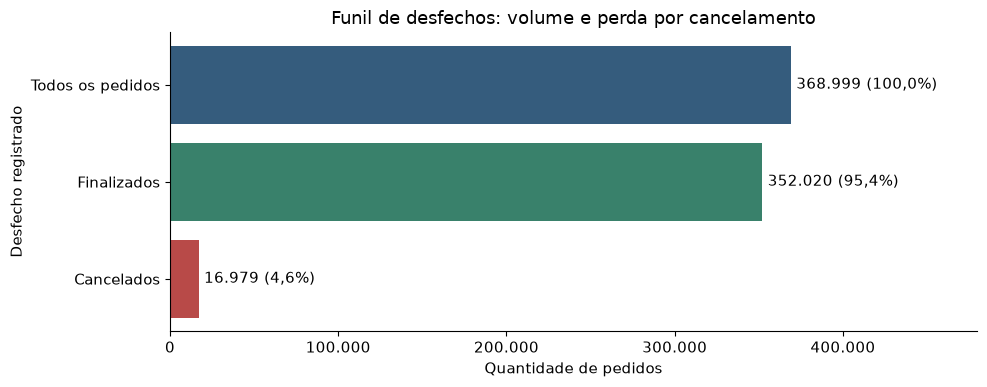

In [4]:
cancelados = int(pedidos.cancelado.sum())
valores = [len(pedidos), int(concluidos.sum()), cancelados]
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(['Todos os pedidos', 'Finalizados', 'Cancelados'], valores,
              color=['#355c7d', '#39816b', '#b84a48'])
ax.invert_yaxis()
ax.bar_label(bars, labels=[f'{fmt_int(n)} ({fmt_pct(n / len(pedidos), 1)})' for n in valores], padding=4)
ax.set(xlabel='Quantidade de pedidos', ylabel='Desfecho registrado',
       title='Funil de desfechos: volume e perda por cancelamento', xlim=(0, len(pedidos) * 1.30))
formatar_eixos(fig); plt.tight_layout(); plt.show()

In [5]:
display(Markdown(f'O arquivo registra **{fmt_int(cancelados)} cancelamentos ({fmt_pct(cancelados / len(pedidos), 2)})**. '
    f'O canal de maior receita é **{por_canal.index[0]}**, com **{fmt_num(por_canal.receita_pct.iloc[0], 2)}%** '
    f'do valor bruto; o segmento líder é **{por_segmento.index[0]} ({fmt_num(por_segmento.receita_pct.iloc[0], 2)}%)** '
    f'e o hub líder é **{por_hub.index[0]} ({fmt_num(por_hub.receita_pct.iloc[0], 2)}%)**. '
    'Priorizar por taxa e volume evita que um canal pequeno com taxa alta domine a decisão.'))

O arquivo registra **16.979 cancelamentos (4,60%)**. O canal de maior receita é **FOOD PLACE**, com **63,67%** do valor bruto; o segmento líder é **FOOD (69,65%)** e o hub líder é **GOLDEN SHOPPING (9,74%)**. Priorizar por taxa e volume evita que um canal pequeno com taxa alta domine a decisão.

## Em que horário o pico pressiona a entrega?

O mapa de calor cruza a hora de criação com o dia da semana, contando **todos os pedidos**. É demanda observada, sem inferir capacidade ou fila. Cada célula reúne o período completo; o recorte inclui quantidades diferentes de cada dia da semana, por isso também calculamos a média por dia observado para identificar o pico.

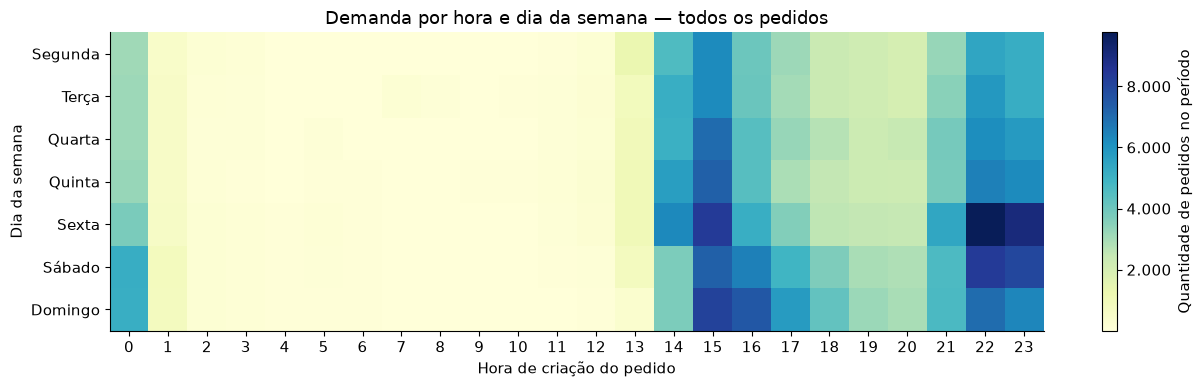

In [6]:
dias = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
grade = pd.crosstab(pedidos.dia_semana, pedidos.order_created_hour).reindex(index=range(7), columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(grade, aspect='auto', cmap='YlGnBu')
ax.set(xticks=range(24), yticks=range(7), yticklabels=dias, xlabel='Hora de criação do pedido',
       ylabel='Dia da semana', title='Demanda por hora e dia da semana — todos os pedidos')
fig.colorbar(im, ax=ax, label='Quantidade de pedidos no período')
formatar_eixos(fig); plt.tight_layout(); plt.show()

In [7]:
datas = pedidos.order_moment_created.dt.normalize()
dias_observados = (pd.DataFrame({'data': datas, 'dia': pedidos.dia_semana})
                   .drop_duplicates().groupby('dia').size())
grade_media = grade.div(dias_observados, axis=0)
pico_dia, pico_hora = grade_media.stack().idxmax()
display(Markdown(f'O pico médio diário aparece em **{dias[pico_dia].lower()}, às {pico_hora}h**, '
    f'com **{fmt_num(grade_media.loc[pico_dia, pico_hora], 1)} pedidos por ocorrência desse dia** '
    f'({fmt_int(grade.loc[pico_dia, pico_hora])} no período). A próxima comparação verifica se esse volume '
    'coincide com ciclos mais longos, sem afirmar causalidade.'))

O pico médio diário aparece em **sexta, às 22h**, com **542,6 pedidos por ocorrência desse dia** (9.766 no período). A próxima comparação verifica se esse volume coincide com ciclos mais longos, sem afirmar causalidade.

### Distribuição do ciclo: cauda longa exige dois retratos

`order_metric_cycle_time` está em minutos: comparamos com `(finished-created)` para verificar a unidade. Usamos somente FINISHED com ciclo positivo no retrato bruto. Para a distribuição operacional, aplicamos **0 < ciclo ≤ 180 minutos**: um limite explícito de três horas para pedidos de entrega imediata. Não é uma regra de SLA da fonte; pode retirar atrasos reais e entregas programadas, sobretudo de bens. Mostramos quantos foram retirados e comparamos mediana/P90 antes e depois; não usamos média como indicador central.

,Amostra,Pedidos,Mediana (min),P90 (min)
0,FINISHED com ciclo positivo,351.657,"42,18","83,17"
1,Recorte operacional até 180 min,332.173,"41,12","67,55"


FINISHED sem ciclo positivo: 363; ciclos acima de 180 min: 19.484 (5,54%)
Diferença absoluta mediana entre métrica e timestamps: 0,0033 min


,pedidos,acima_180_pct
store_segment,,
FOOD,310.548,"0,97"
GOOD,41.109,"40,10"


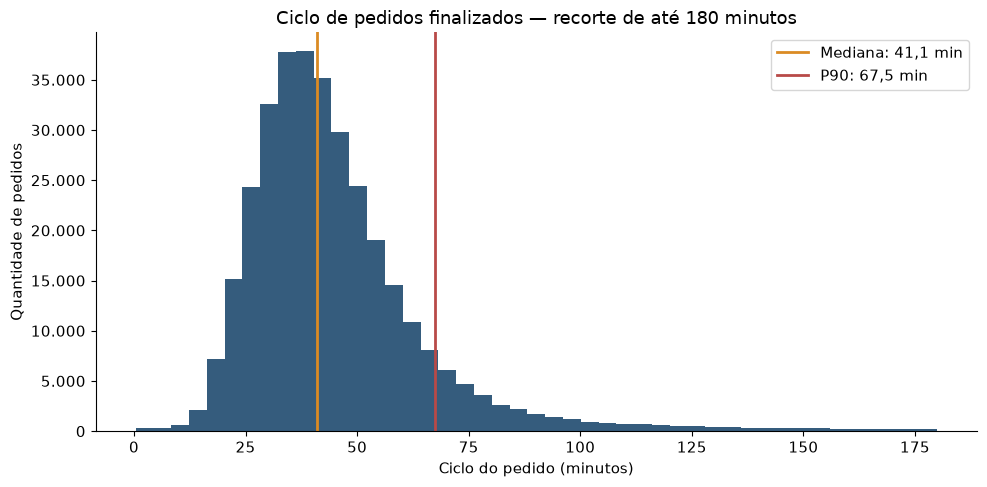

In [8]:
bruto = pedidos.loc[concluidos & pedidos.order_metric_cycle_time.gt(0)].copy()
operacional = bruto.loc[bruto.order_metric_cycle_time.le(180)].copy()
tempo_timestamps = (bruto.order_moment_finished - bruto.order_moment_created).dt.total_seconds() / 60
erro_unidade = (tempo_timestamps - bruto.order_metric_cycle_time).abs().median()
mediana, p90 = operacional.order_metric_cycle_time.quantile([.5, .9])
mediana_bruta, p90_bruto = bruto.order_metric_cycle_time.quantile([.5, .9])
display(tabela_br(pd.DataFrame([
    ['FINISHED com ciclo positivo', len(bruto), mediana_bruta, p90_bruto],
    ['Recorte operacional até 180 min', len(operacional), mediana, p90],
], columns=['Amostra', 'Pedidos', 'Mediana (min)', 'P90 (min)'])))
print(f'FINISHED sem ciclo positivo: {fmt_int(int(concluidos.sum()) - len(bruto))}; '
      f'ciclos acima de 180 min: {fmt_int(len(bruto)-len(operacional))} ({fmt_pct(1-len(operacional)/len(bruto), 2)})')
print(f'Diferença absoluta mediana entre métrica e timestamps: {fmt_num(erro_unidade, 4)} min')
display(tabela_br(bruto.assign(acima_180=bruto.order_metric_cycle_time.gt(180)).groupby('store_segment').agg(
    pedidos=('order_id', 'size'), acima_180_pct=('acima_180', lambda s: s.mean()*100))))
fig, ax = plt.subplots()
ax.hist(operacional.order_metric_cycle_time, bins=45, color='#355c7d')
ax.axvline(mediana, color='#db8b24', linewidth=2, label=f'Mediana: {fmt_num(mediana, 1)} min')
ax.axvline(p90, color='#b84a48', linewidth=2, label=f'P90: {fmt_num(p90, 1)} min')
ax.set(xlabel='Ciclo do pedido (minutos)', ylabel='Quantidade de pedidos',
       title='Ciclo de pedidos finalizados — recorte de até 180 minutos')
ax.legend(); formatar_eixos(fig); plt.tight_layout(); plt.show()

In [9]:
display(Markdown(f'No recorte operacional, a mediana é **{fmt_num(mediana, 2)} min** e o P90 é '
    f'**{fmt_num(p90, 2)} min**. No conjunto bruto positivo, são **{fmt_num(mediana_bruta, 2)} e {fmt_num(p90_bruto, 2)} min**. '
    f'O filtro retira **{fmt_int(len(bruto)-len(operacional))} pedidos** da análise de tempo; '
    'estes continuam nos indicadores comerciais. O P90 descreve a cauda do ciclo observado, não cumprimento de SLA.'))

No recorte operacional, a mediana é **41,12 min** e o P90 é **67,55 min**. No conjunto bruto positivo, são **42,18 e 83,17 min**. O filtro retira **19.484 pedidos** da análise de tempo; estes continuam nos indicadores comerciais. O P90 descreve a cauda do ciclo observado, não cumprimento de SLA.

### Demanda e tempo no mesmo relógio

Comparamos o volume por hora de criação e o P90 do ciclo, tanto bruto quanto no recorte operacional. A tabela complementar separa medianas de produção e trânsito, apenas como pistas de investigação; medianas de etapas não somam necessariamente a mediana do ciclo. Mistura de segmentos, hubs e seleção de finalizados podem explicar diferenças entre horários.

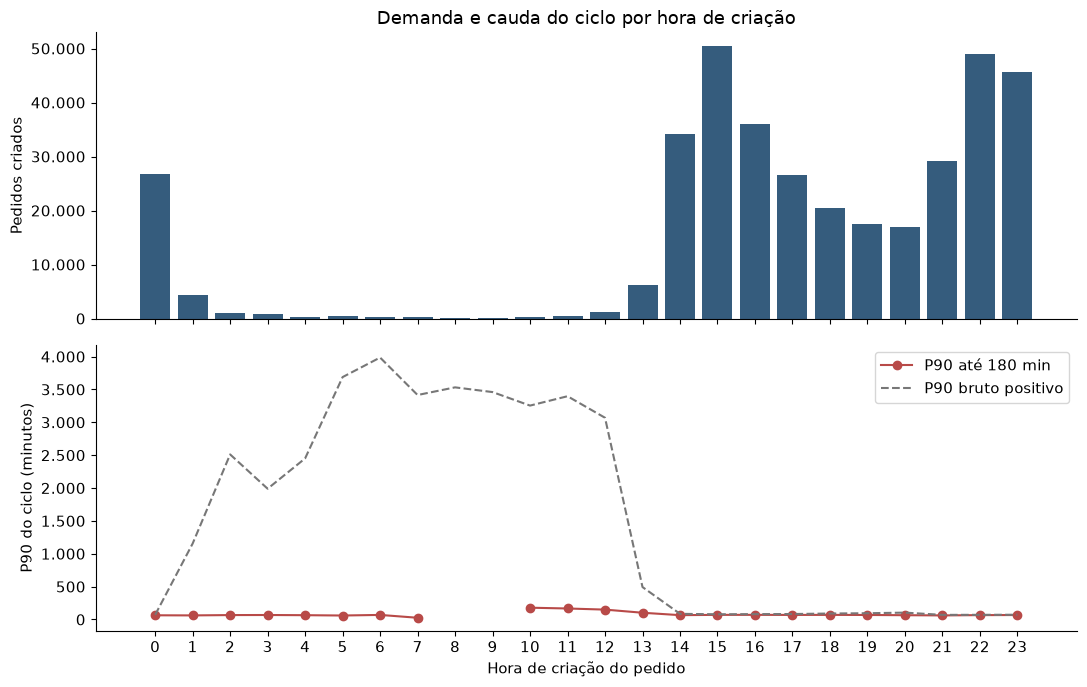

,pedidos,producao_mediana,transito_mediano
order_created_hour,,,
12,273,"24,69","20,84"
15,46.944,"15,78","16,72"


In [10]:
horario = pedidos.groupby('order_created_hour').size().reindex(range(24), fill_value=0)
p90_hora = operacional.groupby('order_created_hour').order_metric_cycle_time.quantile(.9).reindex(range(24))
p90_hora_bruto = bruto.groupby('order_created_hour').order_metric_cycle_time.quantile(.9).reindex(range(24))
fig, (ax, bx) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax.bar(horario.index, horario, color='#355c7d')
ax.set(ylabel='Pedidos criados', title='Demanda e cauda do ciclo por hora de criação')
bx.plot(p90_hora.index, p90_hora, marker='o', label='P90 até 180 min', color='#b84a48')
bx.plot(p90_hora_bruto.index, p90_hora_bruto, linestyle='--', label='P90 bruto positivo', color='#777777')
bx.set(xlabel='Hora de criação do pedido', ylabel='P90 do ciclo (minutos)', xticks=range(24))
bx.legend(); formatar_eixos(fig); plt.tight_layout(); plt.show()
horas_fortes = horario.loc[horario.ge(1000)].index
hora_demanda = int(horario.idxmax())
hora_lenta = int(p90_hora.loc[horas_fortes].idxmax())
etapas = operacional.groupby('order_created_hour').agg(pedidos=('order_id', 'size'),
    producao_mediana=('order_metric_production_time', 'median'),
    transito_mediano=('order_metric_transit_time', 'median'))
display(tabela_br(etapas.loc[sorted({hora_demanda, hora_lenta})]))

In [11]:
display(Markdown(f'O maior volume agregado está às **{hora_demanda}h ({fmt_int(horario.loc[hora_demanda])} pedidos)**, '
    f'com P90 operacional de **{fmt_num(p90_hora.loc[hora_demanda], 2)} min**. Entre horas com ≥1.000 pedidos, '
    f'o maior P90 operacional é às **{hora_lenta}h ({fmt_num(p90_hora.loc[hora_lenta], 2)} min)**. '
    'Volume e cauda de tempo precisam ser monitorados juntos; a evidência não identifica uma causa de gargalo '
    'sem escala de entregadores, fila e controle por hub/segmento.'))

O maior volume agregado está às **15h (50.471 pedidos)**, com P90 operacional de **69,98 min**. Entre horas com ≥1.000 pedidos, o maior P90 operacional é às **12h (150,13 min)**. Volume e cauda de tempo precisam ser monitorados juntos; a evidência não identifica uma causa de gargalo sem escala de entregadores, fila e controle por hub/segmento.

## Quanto custa a entrega por modal?

Uma ordem pode ter várias tentativas de entrega. Para não repetir `order_delivery_cost`, selecionamos pedidos FINISHED com **exatamente uma entrega DELIVERED** e modal conhecido. A tentativa concluída identifica o modal; o custo é o **custo total registrado no pedido**, não remuneração do entregador nem custo marginal dessa tentativa. Exigimos distância > 0 e custo ≥ 0, ambos presentes. Não apararemos valores de custo/distância: exibimos cobertura e medianas como apoio. A razão R$/km é **soma dos custos / soma dos km**, não a média de razões individuais.

FINISHED: 352.020; com uma entrega concluída: 331.006; amostra de custo/distância/modal: 323.861 (92,00%)


,pedidos,custo_total,km_total,custo_medio,custo_mediano,km_medio,km_mediano,reais_km
driver_modal,,,,,,,,
BIKER,92.635,"466.375,27","99.558,98","5,03","5,00","1,07","1,03","4,68"
MOTOBOY,231.226,"1.881.261,21","772.986,13","8,14","8,00","3,34","2,57","2,43"


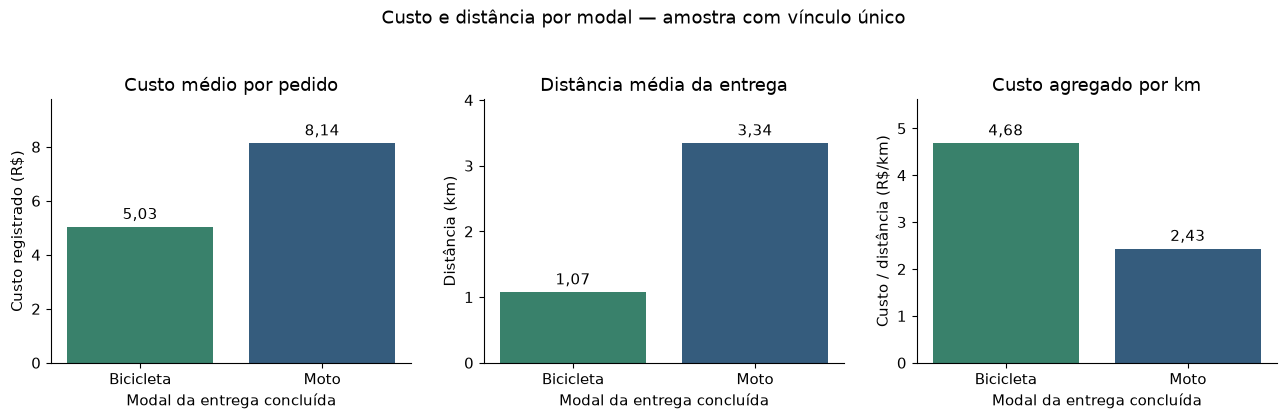

In [12]:
entregues = deliveries.loc[deliveries.delivery_status.eq('DELIVERED')].copy()
unica = entregues.loc[~entregues.delivery_order_id.duplicated(keep=False)]
vinculadas = (pedidos.loc[concluidos, ['order_id', 'delivery_order_id', 'order_delivery_cost']]
    .merge(unica[['delivery_order_id', 'driver_id', 'delivery_distance_meters']],
           on='delivery_order_id', how='inner', validate='one_to_one')
    .merge(drivers, on='driver_id', how='left', validate='many_to_one'))
validas = vinculadas.loc[vinculadas.driver_modal.notna() & vinculadas.order_delivery_cost.ge(0)
                        & vinculadas.delivery_distance_meters.gt(0)].copy()
validas['km'] = validas.delivery_distance_meters / 1000
por_modal = validas.groupby('driver_modal').agg(pedidos=('order_id', 'size'),
    custo_total=('order_delivery_cost', 'sum'), km_total=('km', 'sum'),
    custo_medio=('order_delivery_cost', 'mean'), custo_mediano=('order_delivery_cost', 'median'),
    km_medio=('km', 'mean'), km_mediano=('km', 'median'))
por_modal['reais_km'] = por_modal.custo_total / por_modal.km_total
print(f'FINISHED: {fmt_int(int(concluidos.sum()))}; com uma entrega concluída: {fmt_int(len(vinculadas))}; '
      f'amostra de custo/distância/modal: {fmt_int(len(validas))} ({fmt_pct(len(validas)/concluidos.sum(), 2)})')
display(tabela_br(por_modal))
rotulos = por_modal.index.map({'BIKER': 'Bicicleta', 'MOTOBOY': 'Moto'})
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, coluna, titulo, eixo in zip(axes, ['custo_medio', 'km_medio', 'reais_km'],
    ['Custo médio por pedido', 'Distância média da entrega', 'Custo agregado por km'],
    ['Custo registrado (R$)', 'Distância (km)', 'Custo / distância (R$/km)']):
    bars = ax.bar(rotulos, por_modal[coluna], color=['#39816b', '#355c7d'])
    ax.bar_label(bars, labels=[fmt_num(v, 2) for v in por_modal[coluna]], padding=3)
    ax.set(title=titulo, xlabel='Modal da entrega concluída', ylabel=eixo)
    ax.margins(y=.2)
fig.suptitle('Custo e distância por modal — amostra com vínculo único', y=1.04)
formatar_eixos(fig); plt.tight_layout(); plt.show()

In [13]:
texto_modais = '; '.join(f'{nome}: {fmt_brl(linha.custo_medio)}/pedido, '
    f'{fmt_num(linha.km_medio, 2)} km, {fmt_brl(linha.reais_km)}/km (n={fmt_int(int(linha.pedidos))})'
    for nome, linha in por_modal.iterrows())
display(Markdown('**Custo por modal:** ' + texto_modais + '. As rotas e os perfis dos pedidos diferem: '
    'essa comparação descritiva não mede economia causal ao trocar o modal.'))

**Custo por modal:** BIKER: R$ 5,03/pedido, 1,07 km, R$ 4,68/km (n=92.635); MOTOBOY: R$ 8,14/pedido, 3,34 km, R$ 2,43/km (n=231.226). As rotas e os perfis dos pedidos diferem: essa comparação descritiva não mede economia causal ao trocar o modal.

## Pareto de lojas: quanto depende de poucos parceiros?

Ordenamos **todas as lojas** por valor bruto de pedidos e acumulamos a participação na receita. Cada ponto é uma loja, não o nome agregado de várias lojas; a curva permite medir quantas concentram 80% e qual a participação do top 10. Mantemos cancelados e valores extremos pelo contrato de faturamento, o que exige auditoria antes de uma decisão comercial.

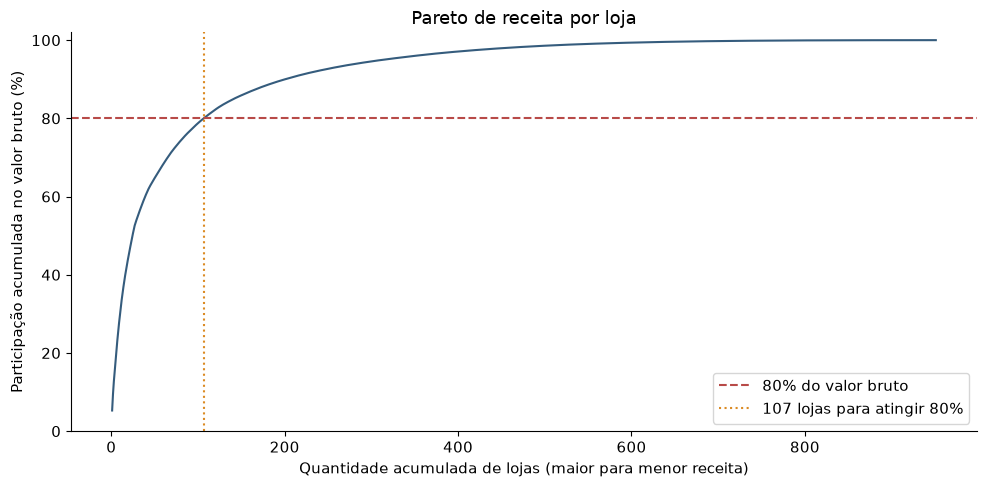

In [14]:
lojas = pedidos.groupby('store_id').order_amount.sum().sort_values(ascending=False)
acumulado = lojas.cumsum() / receita * 100
n80 = int(np.searchsorted(acumulado.to_numpy(), 80) + 1)
top10_pct = lojas.head(10).sum() / receita * 100
fig, ax = plt.subplots()
ax.plot(range(1, len(lojas)+1), acumulado, color='#355c7d')
ax.axhline(80, color='#b84a48', linestyle='--', label='80% do valor bruto')
ax.axvline(n80, color='#db8b24', linestyle=':', label=f'{fmt_int(n80)} lojas para atingir 80%')
ax.set(xlabel='Quantidade acumulada de lojas (maior para menor receita)',
       ylabel='Participação acumulada no valor bruto (%)', title='Pareto de receita por loja', ylim=(0, 102))
ax.legend(); formatar_eixos(fig); plt.tight_layout(); plt.show()

In [15]:
display(Markdown(f'As **10 maiores lojas concentram {fmt_num(top10_pct, 2)}%** do valor bruto. '
    f'São necessárias **{fmt_int(n80)} de {fmt_int(len(lojas))} lojas ({fmt_pct(n80/len(lojas), 2)})** para atingir 80%. '
    'Esse mapa ajuda a priorizar relacionamento e auditoria dos pedidos de maior impacto.'))

As **10 maiores lojas concentram 29,73%** do valor bruto. São necessárias **107 de 951 lojas (11,25%)** para atingir 80%. Esse mapa ajuda a priorizar relacionamento e auditoria dos pedidos de maior impacto.

## Principais achados

Os cinco achados abaixo são construídos diretamente das tabelas anteriores, sem números fixados no texto.

In [16]:
display(Markdown(f"""
- **Base comercial:** {fmt_int(len(pedidos))} pedidos e {fmt_brl(receita)} em valor bruto; {fmt_int(cancelados)} cancelamentos ({fmt_pct(cancelados/len(pedidos), 2)}). Faturamento inclui cancelados para reconciliar com o dashboard.
- **Concentração:** {por_canal.index[0]} reúne {fmt_num(por_canal.receita_pct.iloc[0], 2)}% da receita; {por_segmento.index[0]} soma {fmt_num(por_segmento.receita_pct.iloc[0], 2)}%; o hub {por_hub.index[0]} soma {fmt_num(por_hub.receita_pct.iloc[0], 2)}%. As dez maiores lojas representam {fmt_num(top10_pct, 2)}%.
- **Pico e ciclo:** às {hora_demanda}h são {fmt_int(horario.loc[hora_demanda])} pedidos; P90 operacional nesse horário = {fmt_num(p90_hora.loc[hora_demanda], 2)} min. No recorte completo até 180 min, mediana = {fmt_num(mediana, 2)} e P90 = {fmt_num(p90, 2)} min (bruto: {fmt_num(mediana_bruta, 2)}/{fmt_num(p90_bruto, 2)} min).
- **Custo por modal:** {texto_modais}. Cobertura: {fmt_int(len(validas))} pedidos, {fmt_pct(len(validas)/concluidos.sum(), 2)} dos finalizados.
- **Qualidade financeira:** o maior pedido é R$ {fmt_num(orders.order_amount.max(), 2)}, {fmt_pct(orders.order_amount.max()/receita, 2)} do total; {fmt_int(int(reconciliacao.pagamentos.gt(1).sum()))} pedidos têm mais de um registro de pagamento. Auditar antes de projetar receita realizada.
"""))


- **Base comercial:** 368.999 pedidos e R$ 38.800.730,73 em valor bruto; 16.979 cancelamentos (4,60%). Faturamento inclui cancelados para reconciliar com o dashboard.
- **Concentração:** FOOD PLACE reúne 63,67% da receita; FOOD soma 69,65%; o hub GOLDEN SHOPPING soma 9,74%. As dez maiores lojas representam 29,73%.
- **Pico e ciclo:** às 15h são 50.471 pedidos; P90 operacional nesse horário = 69,98 min. No recorte completo até 180 min, mediana = 41,12 e P90 = 67,55 min (bruto: 42,18/83,17 min).
- **Custo por modal:** BIKER: R$ 5,03/pedido, 1,07 km, R$ 4,68/km (n=92.635); MOTOBOY: R$ 8,14/pedido, 3,34 km, R$ 2,43/km (n=231.226). Cobertura: 323.861 pedidos, 92,00% dos finalizados.
- **Qualidade financeira:** o maior pedido é R$ 1.788.306,11, 4,61% do total; 48.818 pedidos têm mais de um registro de pagamento. Auditar antes de projetar receita realizada.


## Limitações e próximos passos

- Quatro meses de 2021 não representam a operação atual. A marca histórica do case não identifica o universo inteiro do iFood. A licença do catálogo não concede uma licença aberta para os dados.
- Faturamento é valor bruto dos pedidos, inclusive cancelados; não estima margem, repasse ou caixa. Auditar o maior pedido e reconciliar pagamentos, taxas e estornos com documentação contábil.
- Os status são um retrato final; falta trilha de transições para um funil de conversão por etapa e motivos de cancelamento. Comparar volume e taxa por hub/canal com intervalos de incerteza e denominadores suficientes.
- O limite de 180 min pode retirar atrasos legítimos e pedidos programados. Reportar sempre o retrato bruto, distinguir FOOD de GOOD, validar SLA e decompor tempos por etapa/hub antes de sugerir contratação.
- A amostra por modal exclui vínculos ambíguos, distância zero e dados ausentes. Custo total do pedido não é remuneração individual. Ajustar distância, região, horário e tipo de pedido antes de avaliar migração de modal.
- Próximo experimento: monitorar fila, entregadores ativos e P90 por hub nas horas de maior demanda; avaliar intervenção de capacidade com grupo de comparação. Nenhum resultado descritivo aqui comprova um gargalo causal.